In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.15)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [2]:
#updates acceleration based on Newton's laws of gravitation
def acceleration(G, m, r):
    a = np.zeros_like(r)
    for i in range(len(m)):
        for j in range(len(m)):
            if(i != j):
                a[i] += -G*m[j]*(r[i]-r[j])/np.linalg.norm(r[i]-r[j])**3
    return a

In [ ]:
#advances the simulation using the "naive" Leapfrog integration method -> energy is not conserved this way
def update_invleapfrog(G, m, ri, vi, dt):
    a = acceleration(G, m, ri)
    rf = ri + vi * dt
    vf = vi + a * dt
    return rf, vf

In [ ]:
#advances the simulation using the (correct) Leapfrog integration method (note: v_i and x_i are shifted by a half index)
def update_leapfrog(G, m, ri, vi, dt):
    a = acceleration(G, m, ri)
    vf = vi + a * dt
    rf = ri + vf * dt
    return rf, vf

In [ ]:
#advances the simulation using the "kick-drift-kick" method: Leapfrog integration where v_i and x_i are synchronized
def update_kickdriftkick(G, m, ri, vi, ai, dt):
    v_1 = vi + 1/2 * ai * dt
    rf = ri + v_1 * dt
    af = acceleration(G, m, rf)
    vf = v_1 + 1/2 * af * dt
    return rf, vf, af

In [ ]:
#calculates the current kinetic and potential energies
def energy(G, m, r, v):
    U = 0
    E_kin = 0
    for i in range(len(m)):
        E_kin += 1/2 * m[i] * np.linalg.norm(v[i])**2
        for j in range(i+1, len(m), 1):
            U += -G * m[i] * m[j] / np.linalg.norm(r[i]-r[j])
    return U, E_kin

In [ ]:
#pygame setup
W, H = 800, 600
pygame.init()
screen = pygame.display.set_mode((W, H))
pygame.display.set_caption("n-body problem simulation")
clock = pygame.time.Clock()
running = True

#general constants and parameters of the simulation
G=10
dt=0.01

R = 3
colors = ["yellow", "blue", "red", "green", "purple", "white", "orange"]
show_path = False

methods = ["invleapfrog", "leapfrog", "kickdriftkick"]
method = methods[2]

#mass, position, velocity and acceleration matrices
m = np.array([100,10,1])

r1 = np.array([400.0, 300.0])
r2 = np.array([500.0, 300.0])
r3 = np.array([200.0, 200.0])
r = np.array([r1,r2,r3])

v1 = np.array([1, 0])
v2 = np.array([0, -1])
v3 = np.array([0, 0])
v = np.array([v1,v2,v3])

a = acceleration(G,m,r)

E = []
U = []


while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False 

    #drawing the bodies
    if(show_path == False):
        screen.fill("black")
    for i in range(len(m)):
        if(m[i] != 0):
            pygame.draw.circle(screen, colors[i%len(colors)], r[i], R)

    #energy calculation and updating position, velocity and acceleration
    U.append(energy(G,m,r,v)[0])
    E.append(energy(G,m,r,v)[1])
    if(method == "invleapfrog"):
        r,v = update_invleapfrog(G, m, r, v, dt)
    elif(method == "leapfrog"):
        r,v = update_leapfrog(G, m, r, v, dt)
    elif(method == "kickdriftkick"):
        r,v,a = update_kickdriftkick(G, m, r, v, a, dt)

    pygame.display.flip()
    clock.tick(0)

pygame.quit()

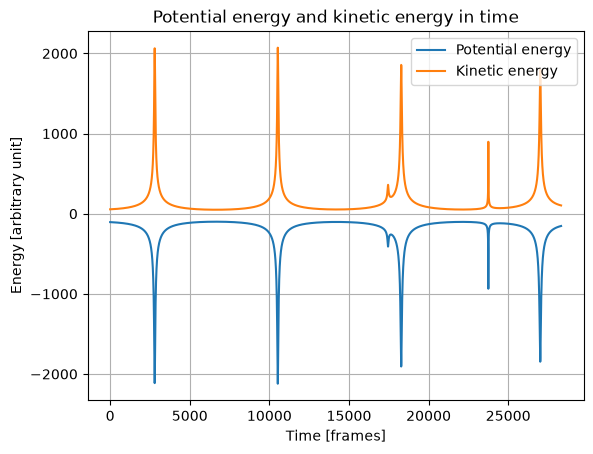

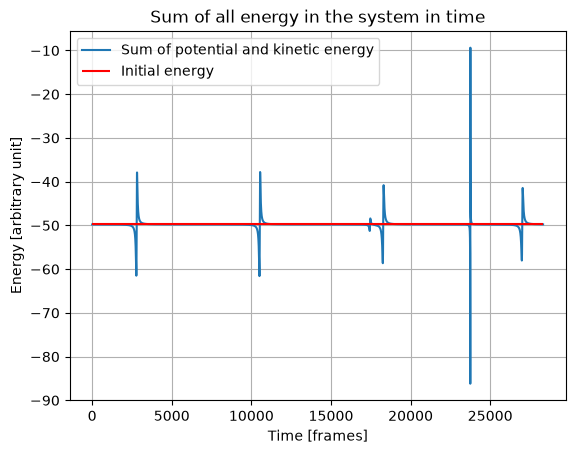

In [7]:
plt.figure()
t = range(0,len(E))

plt.plot(t,U, label="Potential energy")
plt.plot(t,E, label="Kinetic energy")
plt.grid()
plt.xlabel("Time [frames]")
plt.ylabel("Energy [arbitrary unit]")
plt.title("Potential energy and kinetic energy in time")
plt.legend()
plt.show()

plt.plot(t,np.add(E,U), label="Sum of potential and kinetic energy")
plt.hlines(E[0]+U[0],t[0],t[-1],"red", label="Initial energy")
plt.grid()
plt.xlabel("Time [frames]")
plt.ylabel("Energy [arbitrary unit]")
plt.title("Sum of all energy in the system in time")
plt.legend()